# Libraries

In [1]:
%matplotlib inline

In [2]:
from perceval.components.unitary_components import PS, BS
from perceval.rendering.circuit import DisplayConfig, SymbSkin
import numpy as np
from pathlib import Path
import perceval as pcvl
from perceval import BasicState
import os
import glob
import time
from datetime import datetime
from tqdm import tqdm

import itertools as it
from scipy.optimize import minimize

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from tqdm.auto import tqdm

from scipy.optimize import minimize, OptimizeResult
from scipy.optimize import dual_annealing
from uncertainties import unumpy
import ipywidgets as widgets
from IPython.display import display, clear_output
from uncertainties import ufloat

# Circuit Design

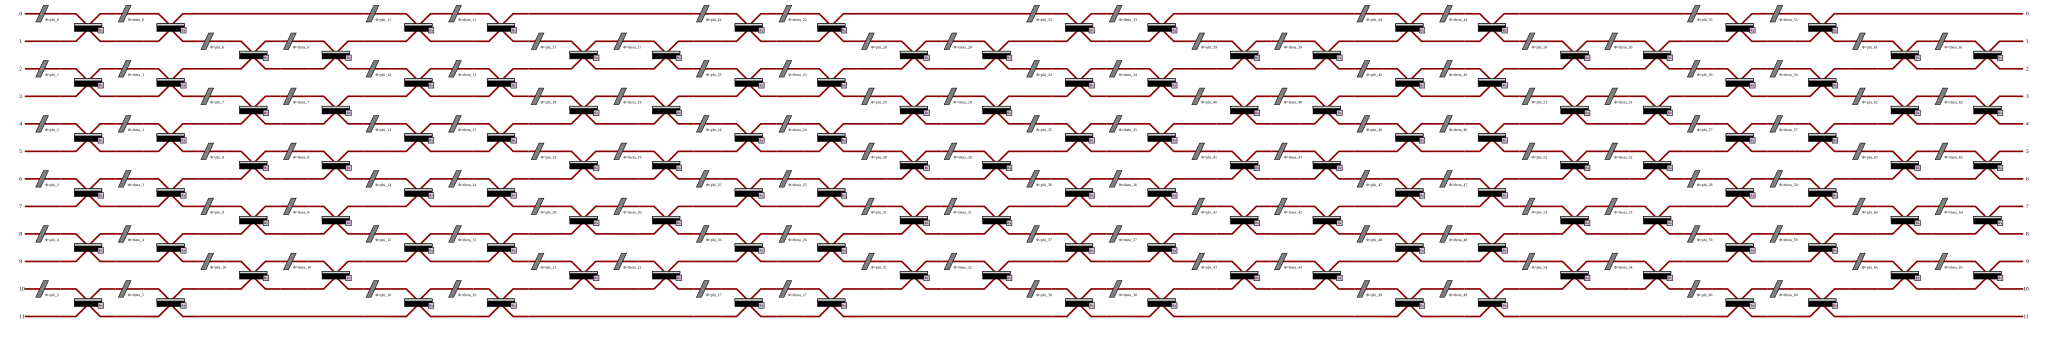

In [3]:
m = 12

circuit = pcvl.components.GenericInterferometer(m,
                                fun_gen = lambda idx: (pcvl.Circuit(2, name='mzi')
                                                       .add(0, PS(pcvl.P(f"phi_{idx}"))))
                                                       .add(0, BS())
                                                       .add(0, PS(pcvl.P(f"theta_{idx}")))
                                                       .add(0, BS()),
                                                shape= pcvl.InterferometerShape.RECTANGLE)
pcvl.pdisplay(circuit)

# Parameters, Input and Output States

In [4]:
parameters = circuit.get_parameters()
par_e = parameters[::2]
par_i = parameters[1::2]

In [5]:
out_states = [[1,0,1,0],[1,0,0,1],[0,1,1,0],[0,1,0,1]]
out_states = [[0,0]+j+[0]*6 for j in out_states]
out_states = [pcvl.BasicState(i) for i in out_states]
out_states

[|0,0,1,0,1,0,0,0,0,0,0,0>,
 |0,0,1,0,0,1,0,0,0,0,0,0>,
 |0,0,0,1,1,0,0,0,0,0,0,0>,
 |0,0,0,1,0,1,0,0,0,0,0,0>]

In [6]:
V = 1

x = np.arccos(2*V-1)
v1 = BasicState("|{0}>")
v2 = pcvl.StateVector("|{1}>")
phase = complex(np.exp(1j*x))
in_state = BasicState("|0,0>")*(v1+v2)*BasicState("|0>")*(v1+phase*v2)*BasicState("|0,0,0,0,0,0,0>")
in_state

0.5*|0,0,{1},0,{1},0,0,0,0,0,0,0>+0.5*|0,0,{0},0,{0},0,0,0,0,0,0,0>+0.5*|0,0,{1},0,{0},0,0,0,0,0,0,0>+0.5*|0,0,{0},0,{1},0,0,0,0,0,0,0>

# Simulation Functions



## Circuit Simulation

In [7]:
processor = pcvl.Processor("Naive")

In [8]:
calls = 0

def circ_sim(f_i, f_e, n_shots=1e9):
    global calls
    calls += 1

    for i,p in enumerate(par_e):
        p.set_value(f_e[i])

    for j,q in enumerate(par_i):
        q.set_value(f_i[j])

    processor.set_circuit(circuit)
    simulator = pcvl.SimulatorFactory().build(processor)

    P_I = [] 

    for s in out_states:
        p_I = simulator.probability(in_state,s)
        P_I.append(p_I)

    PP = np.array(P_I)
    CC = np.random.poisson(PP*n_shots)

    return CC

'10parameters' scheme

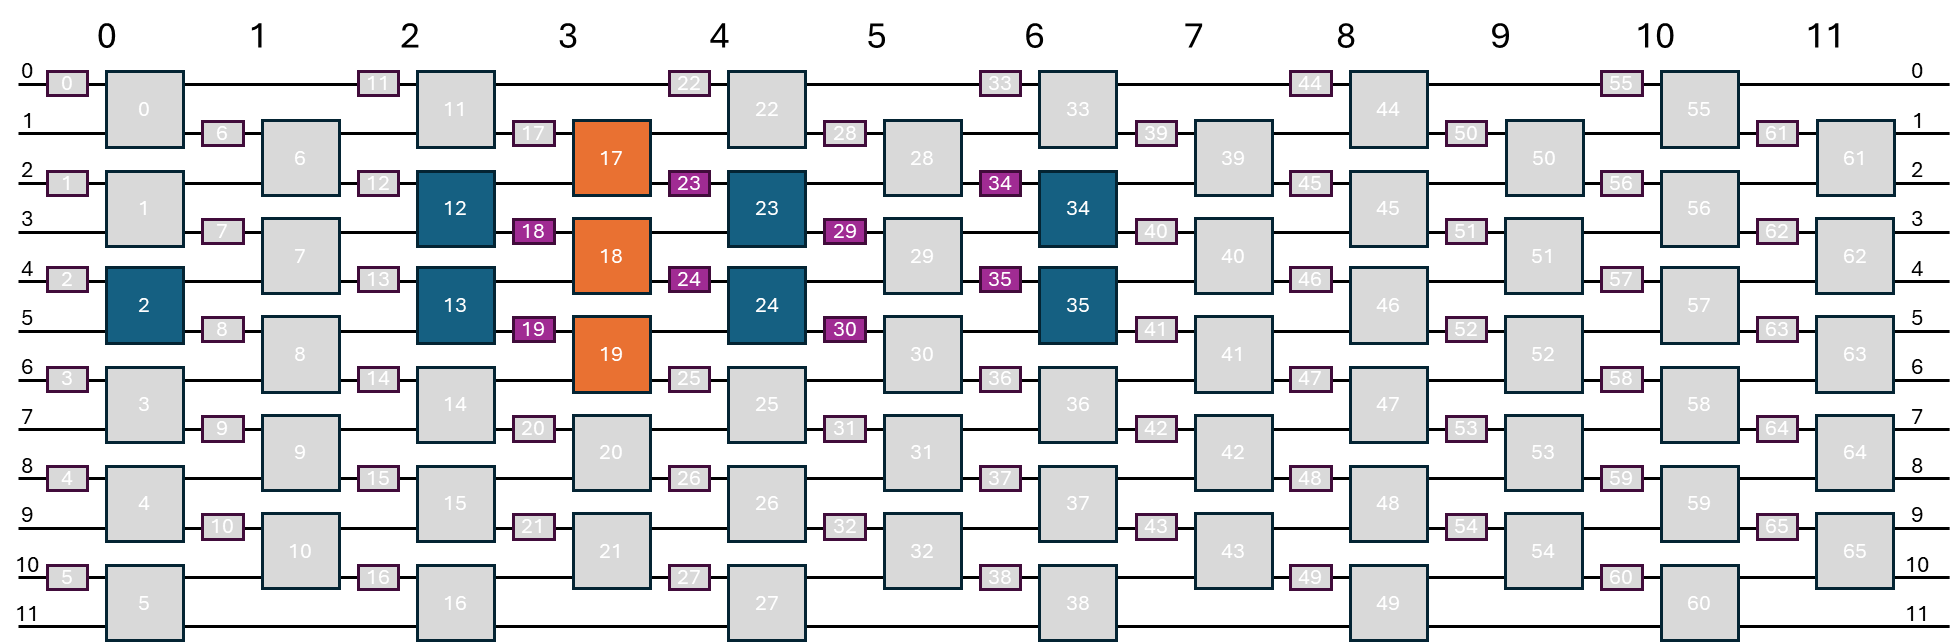

'qlass' scheme

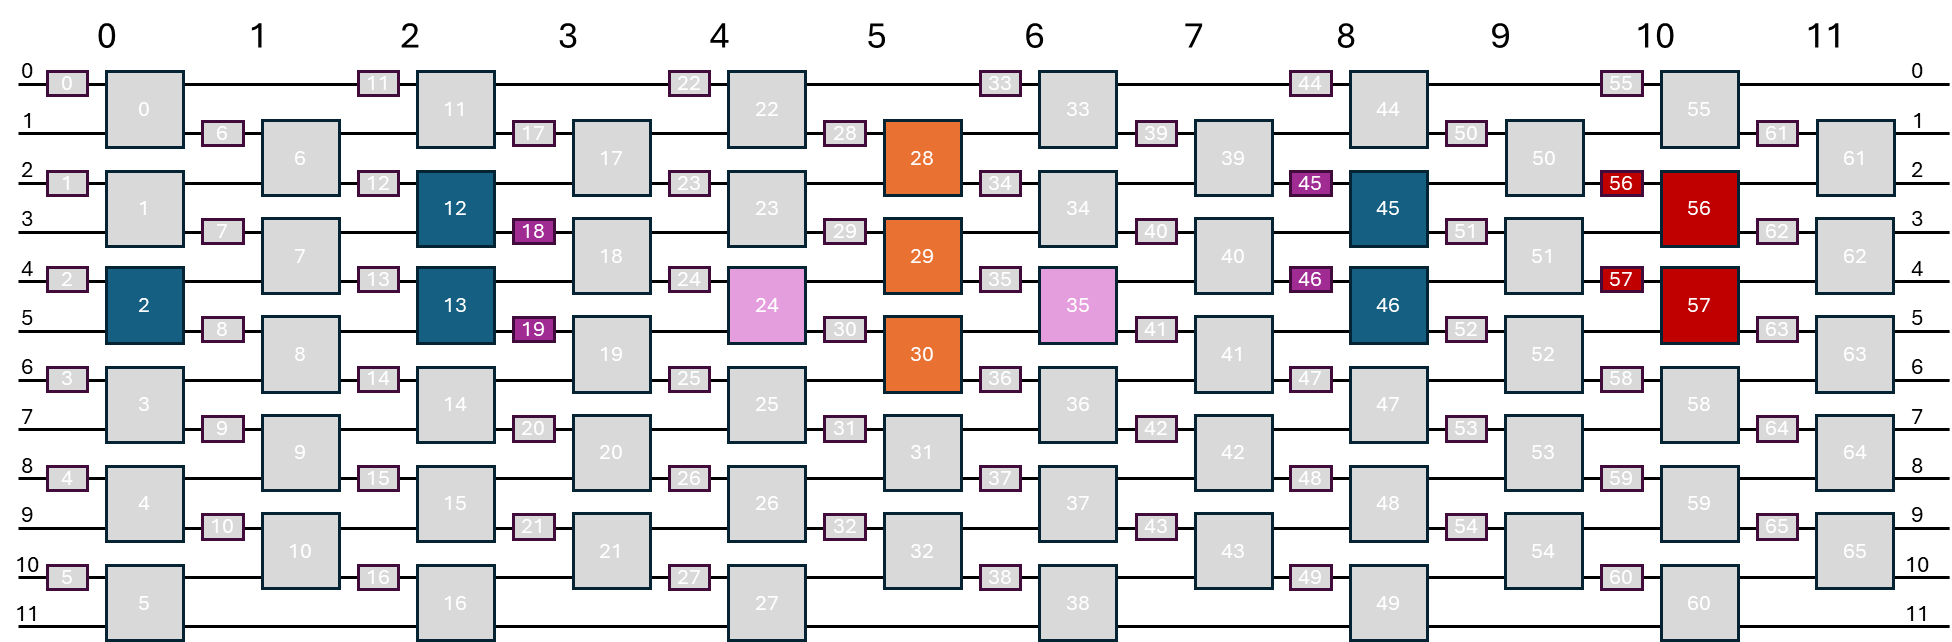

## Measurement function

In [9]:
def P_calc(x, measurement_group, inv = False, scheme='qlass'):
    if scheme == '10parameters':
        theta_par = [12,13,23,24]
        phi_par = [18,19,23,24,29,30]
        theta_cnot = [17,18,19]
        theta_meas = [34,35]
        phi_meas = [34,35]
        inv_c = 2
        
        # chip initialization
        theta = np.full(66,np.pi)
        phi = np.zeros(66)
        
        # set internal and external phases
        theta[theta_cnot] = [np.arccos(1/3)]*3
        theta[theta_par] = x[:len(theta_par)]
        phi[phi_par] = x[len(theta_par):]

    if scheme == 'qlass':
        theta_par = [12,13,45,46]
        theta_cnot_ext = [24,35]
        theta_cnot = [28,29,30]
        theta_meas = [56,57]
        phi_meas = [56,57]
        offset_phases = [23,24,29,40,45,46,51,52]
        inv_c = 2

        # chip initialization
        theta = np.full(66,np.pi)
        phi = np.zeros(66)
        
        # set internal and external phases
        theta[theta_cnot] = [-np.arccos(1/3),-np.arccos(1/3),np.arcsin(1/3)]
        theta[theta_cnot_ext] = [np.pi/2]*2
        # thetas_from_R = 2*np.arcsin(x)
        theta[theta_par] = x
        phi[offset_phases] = np.pi
    
    if inv:
        theta[inv_c] = 0

    meas_circ = {'X': {'phi': [0], 'theta': [np.pi/2]},
                 'Y': {'phi': [np.pi/2], 'theta': [np.pi/2]},
                 'Z': {'phi': [0], 'theta': [np.pi]}}

    results = {}
    for op in measurement_group:
        theta[theta_meas] = meas_circ[op[0]]['theta'] + meas_circ[op[1]]['theta']
        phi[phi_meas]     = meas_circ[op[0]]['phi']   + meas_circ[op[1]]['phi']
        results[op] = circ_sim(theta, phi)
    return results

## Hamiltonian and gradient computation

In [10]:
def expected_value(cc, A, B, eig, tot=None):
    signs = np.kron(eig[A], eig[B])
    if tot == None:
        tot = cc.sum()
    if tot == 0:
        return 0
    return (signs * cc).sum() / tot

def S1(x, H_terms, measurement_groups, inv = False, Error = False, scheme = 'qlass'):

    n = len(x)

    results = P_calc(x, measurement_groups, inv, scheme = scheme)
    if Error:
        results = {k: unumpy.uarray(v, np.sqrt(v + 1)) for k, v in results.items()}
        
    # Hamiltonian computation

    eig = {'I': np.array([1,  1]),
           'X': np.array([1, -1]),
           'Y': np.array([1, -1]),
           'Z': np.array([1, -1])}
    
    pauli_groupings = {'II': 'II', 'IX': 'XX', 'IY': 'YY', 'IZ': 'ZZ',
                       'XI': 'XX', 'XX': 'XX', 'XY': 'XY', 'XZ': 'XZ',
                       'YI': 'YY', 'YX': 'YX', 'YY': 'YY', 'YZ': 'YZ',
                       'ZI': 'ZZ', 'ZX': 'ZX', 'ZY': 'ZY', 'ZZ': 'ZZ'}
     
    exp_values = ({op: expected_value(results[pauli_groupings[op]],op[0],op[1],eig) for op in H_terms if op != 'II'})
    exp_values['II'] = 1

    coeffs = np.array(list(H_terms.values()))
    expval  = np.array([exp_values[op] for op in H_terms])
    H = coeffs @ expval

    # gradient computation
    if not Error:
        grad_H = []
        for i in range(n):
            x_s = np.copy(x)
            x_s[i] += np.pi/2
            res1 = P_calc(x_s, measurement_groups, inv, scheme = scheme)
            
            x_s = np.copy(x)
            x_s[i] -= np.pi/2
            res2 = P_calc(x_s, measurement_groups, inv, scheme = scheme)

            dres = {op: (res1[op] - res2[op])/2 for op in measurement_groups}
            dres['II'] = np.array([0])
            
            dexp_values = ({op: expected_value(dres[pauli_groupings[op]],op[0],op[1],eig, tot=results[pauli_groupings[op]].sum()) - exp_values[op] * dres[pauli_groupings[op]].sum() / results[pauli_groupings[op]].sum() for op in H_terms if op != 'II'})
            dexp_values['II'] = 0
            dexpval = np.array([dexp_values[op] for op in H_terms])
            dH = coeffs @ dexpval
            grad_H.append(dH)
            
        return H, np.array(grad_H)
    else:
        return H.nominal_value, H.std_dev

def S(x, H_terms, measurement_groups, weights, scheme):
    H1, Grad1 = S1(x, H_terms, measurement_groups, inv=False, Error=False, scheme = scheme)
    H2, Grad2 = S1(x, H_terms, measurement_groups, inv=True, Error=False, scheme = scheme)
    return weights[0]*H1 + weights[1]*H2, weights[0]*Grad1 + weights[1]*Grad2

In [11]:
def expected_value(cc, A, B, eig, tot=None):
    signs = np.kron(eig[A], eig[B])
    if tot == None:
        tot = cc.sum()
    # if tot == 0:
    #     return 0
    return (signs * cc).sum() / tot

def S1_energy(x, H_terms, measurement_groups, inv = False, Error = False, scheme = 'qlass'):
    
    n = len(x)

    results = P_calc(x, measurement_groups, inv, scheme = scheme)
    
    if Error:
        results = {k: unumpy.uarray(v, np.sqrt(v + 1)) for k, v in results.items()}
        
    # Hamiltonian computation

    eig = {'I': np.array([1,  1]),
           'X': np.array([1, -1]),
           'Y': np.array([1, -1]),
           'Z': np.array([1, -1])}
    
    pauli_groupings = {'II': 'II', 'IX': 'XX', 'IY': 'YY', 'IZ': 'ZZ',
                       'XI': 'XX', 'XX': 'XX', 'XY': 'XY', 'XZ': 'XZ',
                       'YI': 'YY', 'YX': 'YX', 'YY': 'YY', 'YZ': 'YZ',
                       'ZI': 'ZZ', 'ZX': 'ZX', 'ZY': 'ZY', 'ZZ': 'ZZ'}
     
    exp_values = ({op: expected_value(results[pauli_groupings[op]],op[0],op[1],eig) for op in H_terms if op != 'II'})
    if Error:
        exp_values['II'] = ufloat(1,0)
    else:
        exp_values['II'] = 1
    coeffs = np.array(list(H_terms.values()))
    expval  = np.array([exp_values[op] for op in H_terms])
    H = coeffs @ expval
    if not Error:
        return H
    else:
        return H.nominal_value, H.std_dev

def S_energy(x, H_terms, measurement_groups, weights, scheme = 'qlass'):
    H1 = S1_energy(x, H_terms, measurement_groups, inv=False, Error=False, scheme = scheme)
    H2 = S1_energy(x, H_terms, measurement_groups, inv=True, Error=False, scheme = scheme)
    return weights[0]*H1 + weights[1]*H2

In [12]:
def hamiltonian_matrix(H_terms, dim=4):
    sigma = {'I': np.array([[1,0],[0,1]], dtype=complex),
             'X': np.array([[0,1],[1,0]], dtype=complex),
             'Y': np.array([[0,-1j],[1j,0]], dtype=complex),
             'Z': np.array([[1,0],[0,-1]], dtype=complex)}
    H = np.zeros((dim,dim), dtype=complex)
    for pauliop, coeff in H_terms.items():
        O = np.kron(sigma[pauliop[0]],sigma[pauliop[1]])
        H += coeff * O
    eigenvalues = np.sort(np.linalg.eigvals(H)).real
    return H, eigenvalues

In [13]:
def ground_state(x, H_terms, measurement_groups, weights):
    H1 = S1_energy(x, H_terms, measurement_groups, inv=False, Error=False)
    # H2 = S1_energy(x, H_terms, measurement_groups, inv=True, Error=False)
    return H1

# Simulation

In [14]:
N = 1
N_par = 4
SCHEME = 'qlass'

# fix the inital conditions to compare different simulations
r0 = [np.random.uniform(0,2*np.pi,N_par) for _ in range(N)]
# r0 = [np.random.rand(N_par) for _ in range(N)]

In [15]:
# Iteration 1
shots = 1e9
n_qubits = 2
n_occ = 2 # number of occupied states
# params = np.random.rand(4)
dim = 2 ** n_qubits

H_1 = {'II': -0.44216633, 'IX':-0.2458943, 'IZ':-0.36997974, 'XI':-0.07340748, 'XX':0.00097788, 'XZ':0.07417185, 'YY': 0.03523796, 'ZI':-0.44476681, 'ZX':-0.04444575, 'ZZ':-0.41780773}
# H_1 = {'II': -0.44216633, 'XI': -0.44216633, 'ZI':-0.4447668} # this works
measurement_groups = ['ZZ', 'XX', 'XZ', 'ZX', 'YY']
weights = [0.5, 0.5]

In [16]:
H1, energies = hamiltonian_matrix(H_1, dim)
energies

array([-1.72864826, -0.2473062 , -0.04887898,  0.25616812])

In [17]:
log_output = widgets.Output()
display(log_output)

Output()

In [18]:
plot_output = widgets.Output()
display(plot_output)

Output()

In [ ]:
os.makedirs('Simulations/DFT', exist_ok=True)


def callback(x, H_terms, measurement_groups, weights, E0_true = -1.72864826, E1_true = -0.2473062):
    global E
    v1,e1 = S1_energy(x, H_terms, measurement_groups, inv = False, Error = True, scheme = SCHEME)
    v2,e2 = S1_energy(x, H_terms, measurement_groups, inv = True, Error = True, scheme = SCHEME)
    
    cost.append(weights[0]*v1 + weights[1]*v2)
    E1.append(v1)
    E2.append(v2)

    cost_e.append(weights[0]*e1 + weights[1]*e2)
    E1_e.append(e1)
    E2_e.append(e2)

    trace.append(v1+v2)
    trace_e.append(e1+e2)
    
    trace_true = E0_true + E1_true
    cost_true = weights[0]*E0_true + weights[1]*E1_true
    
    xs = np.arange(len(cost))
    with plot_output:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.set_xlabel("Step")
        ax.set_ylabel("E (Hartree)")
        ax.axhline(y=trace_true, color='green', linewidth=1, label='trace')
        ax.axhline(y=cost_true, color='blue', linewidth=1, label='cost')
        # ax.axhline(y=-7.71405669, color='red', linewidth=1, label='2nd excited')
        ax.errorbar(xs, trace, trace_e, fmt='g.', capsize=3)
        ax.plot(xs, trace, 'go-', linewidth=1)
        ax.errorbar(xs, cost, cost_e, fmt='g.', capsize=3)
        ax.plot(xs, cost, 'o-', color='blue', linewidth=1)
        ax.set_title(f"Run {k}  |  step {len(cost)-1}  | Calls {calls} | ΔE={cost[-1]-E0_true:+.5f}")
        ax.legend()
        plt.tight_layout()
        plt.show()
        plt.close(fig)

for k in tqdm(range(N)):
    calls = 0
    cost = []
    E1 = []
    E2 = []
    cost_e = []
    E1_e = []
    E2_e = []
    trace = []
    trace_e = []
    
    # res = minimize(S, x0 = r0[k], args = (H_1, measurement_groups, weights), method = 'BFGS', jac = True, callback = lambda x: callback(x, H_1, measurement_groups, weights))
    res = minimize(S_energy, x0 = r0[k], args = (H_1, measurement_groups, weights, SCHEME), method = 'COBYLA', callback = lambda x: callback(x, H_1, measurement_groups, weights, energies[0], energies[1]))
    optimized_parameters = res.x
    with log_output:
        print(f'Total calls: {calls}')
    # np.savez(f'Simulations/DFT/DFT_run_{k:03d}', calls = calls, E = E, E1 = E1, E2 = E2, E_e = E_e, E1_e = E1_e, E2_e = E2_e) 

  0%|          | 0/1 [00:00<?, ?it/s]

# Measurement analysis

In [16]:
data = np.load(f'../measurements/2026-05-19/DFT_run_000.npz')
E1_exp = np.array(data['E1'])
E2_exp = np.array(data['E2'])
cost_exp = np.array(data['cost'])
calls_exp = data['calls']

C:\Users\Giovanni\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


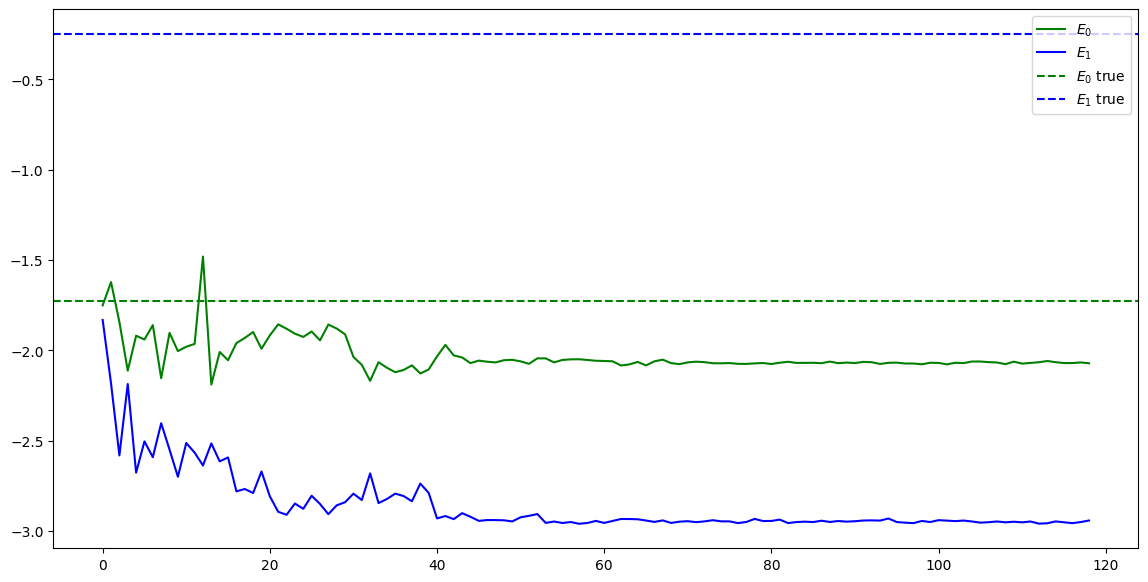

In [17]:
fig, ax = plt.subplots(figsize=(14,7))

ax.plot(range(len(E1_exp)), E1_exp, color='green', label=f'$E_0$')
ax.plot(range(len(E2_exp)), E2_exp, color='blue', label=f'$E_1$')
ax.axhline(energies[0], ls='--', color='green', label=f'$E_0$ true')
ax.axhline(energies[1], ls='--', color='blue', label=f'$E_1$ true')

ax.legend()
plt.show()

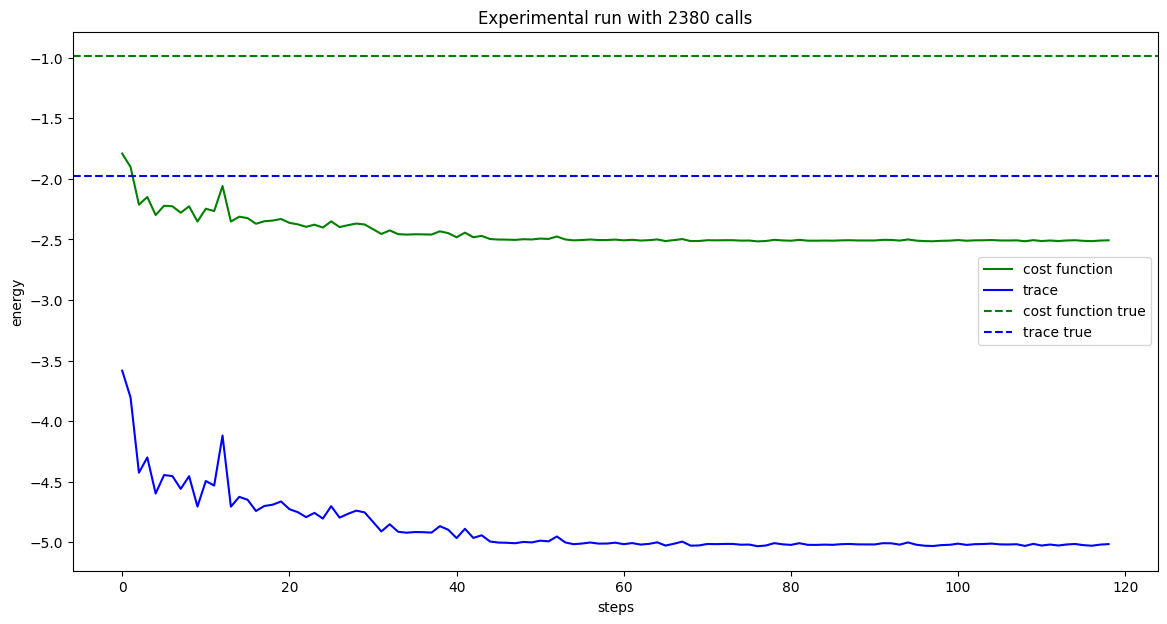

In [18]:
fig, ax = plt.subplots(figsize=(14,7))

trace = np.array(E1_exp)+np.array(E2_exp)

ax.plot(range(len(cost_exp)), cost_exp, color='green', label=f'cost function')
ax.plot(range(len(trace)), trace, color='blue', label=f'trace')
ax.axhline(0.5*energies[0]+0.5*energies[1], ls='--', color='green', label=f'cost function true')
ax.axhline(energies[0]+energies[1], ls='--', color='blue', label=f'trace true')
ax.set_title(f'Experimental run with {calls_exp} calls')
ax.set_ylabel(f'energy')
ax.set_xlabel(f'steps')
ax.legend()
plt.show()